**Complete Iris Classification Project: Logistic Regression vs. Random Forest vs. XGBoost**

In [5]:
# In a new environment, uncomment:
# %pip install -U numpy pandas matplotlib seaborn scikit-learn xgboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectFromModel, RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc, precision_recall_curve, average_precision_score)
from sklearn.inspection import permutation_importance
RANDOM_STATE=42
sns.set_theme(style='whitegrid')

Goal: Compare three classifiers fairly using EDA, leakage-safe preprocessing, feature selection, cross-validation, hyperparameter tuning, multiclass ROC-AUC, and a final held-out test. Iris has 150 observations, four numeric predictors and three balanced classes. Some techniques are experiments, not requirements.
Evaluation protocol: Hold out 20% stratified test data at the start. Use 5-fold stratified CV on the remaining 80% for selection and tuning. Never use the test set to choose a model or threshold.

In [11]:
iris=load_iris(as_frame=True)
X=iris.data.copy()
y=iris.target.copy()
df=X.assign(species=y.map(dict(enumerate(iris.target_names))))
print('Shape:',df.shape)
print('Class labels:',dict(enumerate(iris.target_names)))
display(df.head())
display(df.describe(include='all'))



Shape: (150, 5)
Class labels: {0: np.str_('setosa'), 1: np.str_('versicolor'), 2: np.str_('virginica')}


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


**Data Quality Checks**

In [14]:
##Completeness
print('Missing values:\n',df.isna().sum())
print('Duplicate rows:',df.duplicated().sum())
print('Class distribution:\n',df.species.value_counts())

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64
Duplicate rows: 1
Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Explaination**
There are no missing data in the data set. There is one duplicate data we will look at and determine if it is a legitamate observation or an error. Next step we will look at the outliers and explore the data distributions further. 

**Split Data into Training & Testing**

In [15]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=RANDOM_STATE)
print('Training:',X_train.shape,'Test:',X_test.shape)
print('Train class counts:',y_train.value_counts().sort_index().to_dict())
print('Test class counts:',y_test.value_counts().sort_index().to_dict())
train_df=X_train.assign(species=y_train.map(dict(enumerate(iris.target_names))))

Training: (120, 4) Test: (30, 4)
Train class counts: {0: 40, 1: 40, 2: 40}
Test class counts: {0: 10, 1: 10, 2: 10}


**Exploratory analysis**

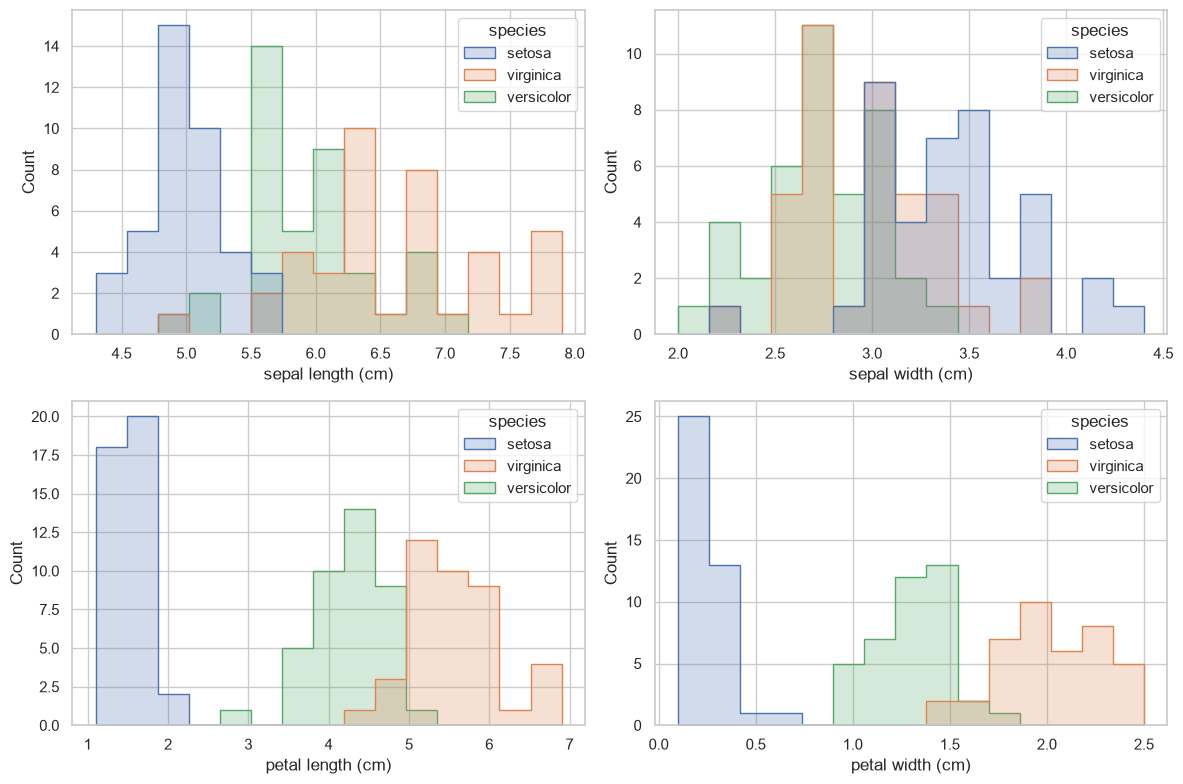

In [17]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,X_train.columns):
    sns.histplot(data=train_df,x=col,hue='species',bins=15,element='step',ax=ax,common_norm=False)
plt.tight_layout();plt.show()


The histograms show the distribution of sepal length, sepal width, petal length, and petal width across the three Iris species. Petal length and petal width appear to be the strongest features for classification, as they clearly distinguish Setosa from the other species, with relatively little overlap between Versicolor and Virginica. In contrast, sepal length and sepal width show greater overlap, suggesting weaker individual predictive power. These findings indicate that petal measurements are likely to be important predictors in our Logistic Regression, Random Forest, and XGBoost models. Further correlation analysis and feature importance evaluation will help confirm their predictive value.

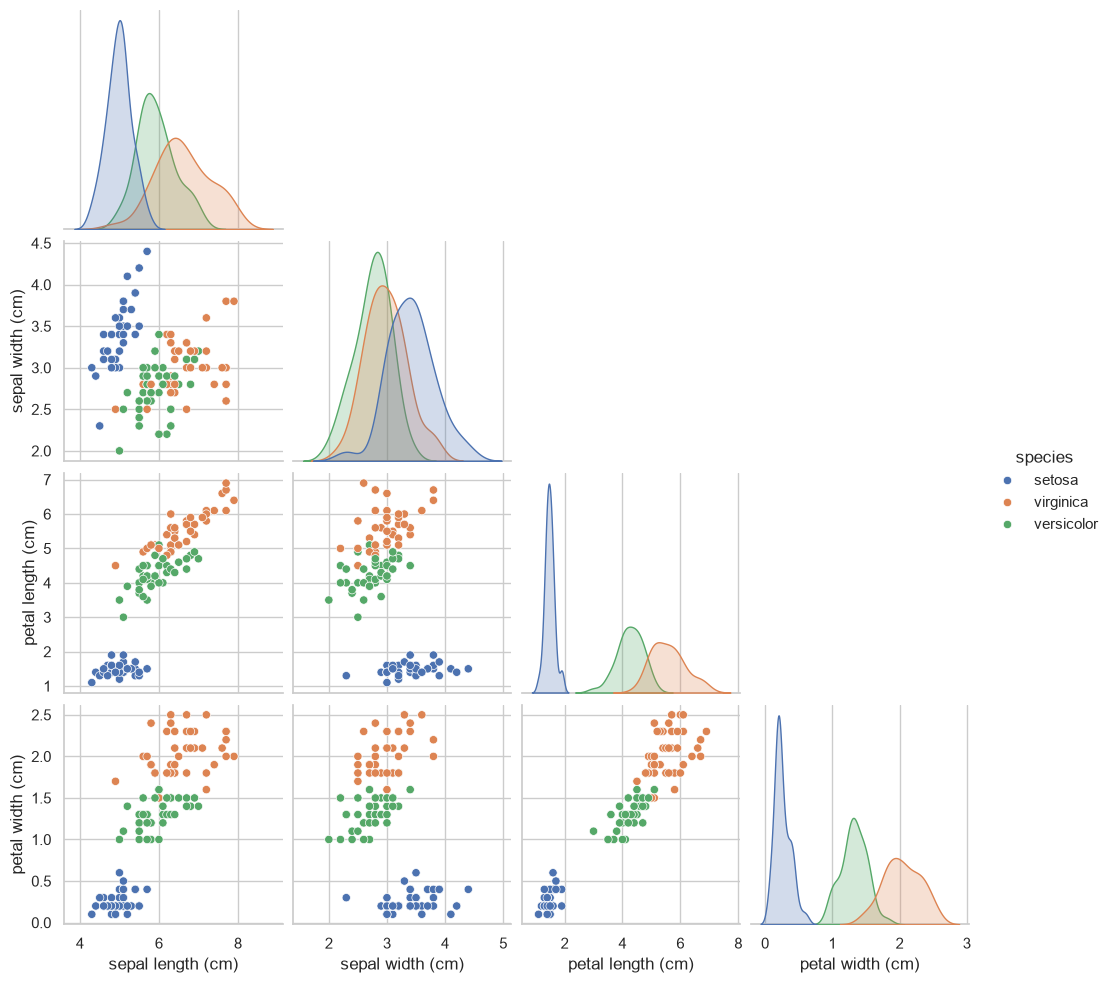

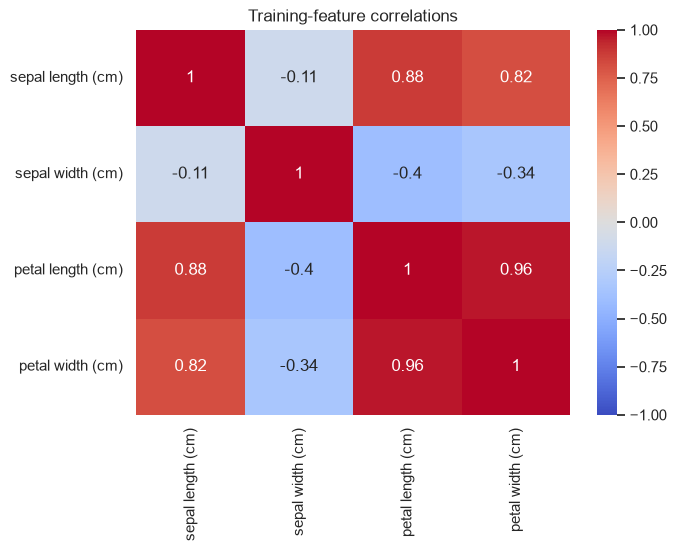

In [19]:

sns.pairplot(train_df,hue='species',corner=True);plt.show()
plt.figure(figsize=(7,5));sns.heatmap(X_train.corr(),annot=True,cmap='coolwarm',vmin=-1,vmax=1);plt.title('Training-feature correlations');plt.show()


**Interpretation**
Pairplot and Correlation Analysis

We use a pairplot to visualize relationships between numerical features and identify how well they separate the three Iris species. The scatterplots show that Setosa forms a distinct cluster, particularly for petal measurements, while Versicolor and Virginica exhibit some overlap. Petal length and petal width show a strong positive relationship, suggesting they are important features for classification.

The correlation heatmap measures the strength of linear relationships between features. Petal length and petal width have a very strong positive correlation (0.96), while sepal length is also strongly correlated with petal length (0.88) and petal width (0.82). Sepal width shows relatively weak negative correlations with the other features.

Conclusion: Petal length and petal width appear to be the strongest predictors for distinguishing Iris species. However, their high correlation (0.96) indicates potential multicollinearity, particularly for Logistic Regression. We will investigate this during feature selection to determine whether removing redundant features improves model performance. Random Forest and XGBoost are generally less sensitive to multicollinearity.

Note: Correlation measures the relationship between two features, not how well a feature predicts the target variable. Some of the strong correlations may partly reflect differences between species, rather than relationships within each species. For Logistic Regression, highly correlated predictors can make individual coefficients unstable and harder to interpret. "Multiculinarity". For Random Forest and XGBoost, correlated predictors are generally less problematic for prediction, although they can complicate feature importance interpretation. Further analysis should be done to understand the correlations.

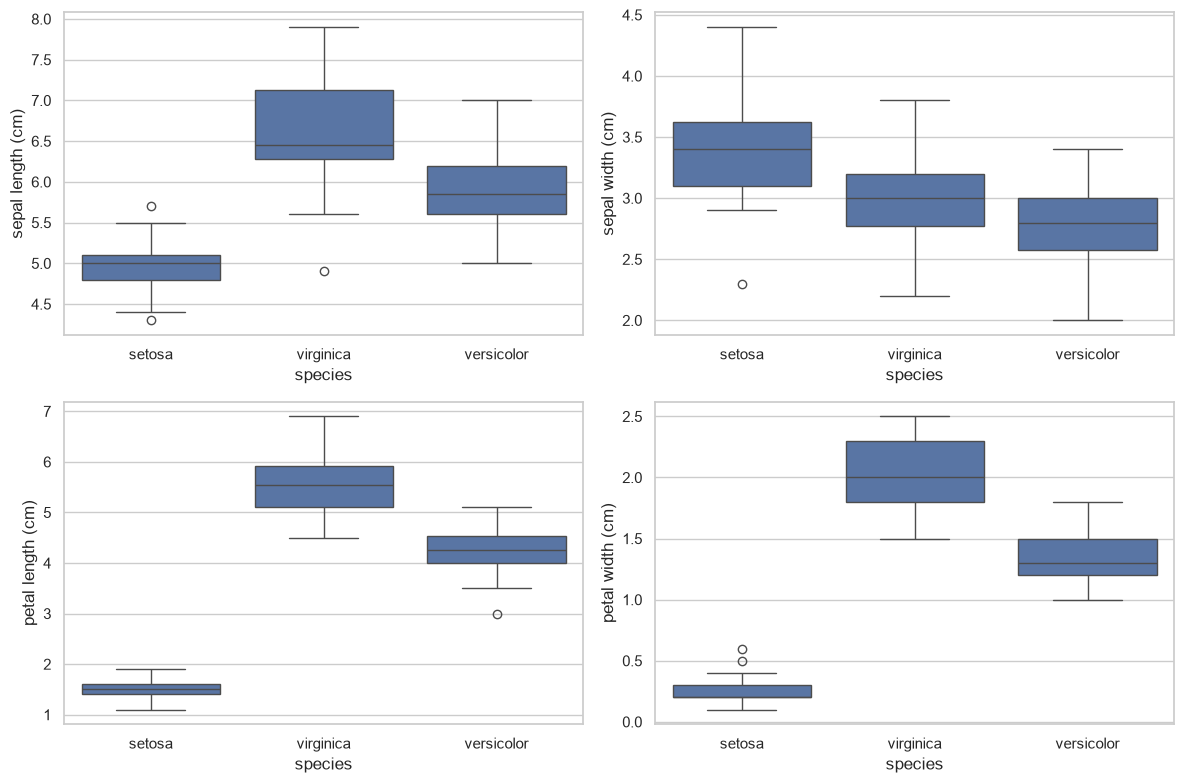

In [21]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,col in zip(axes.flat,X_train.columns):
    sns.boxplot(data=train_df,x='species',y=col,ax=ax)
plt.tight_layout();plt.show()



**Boxplot Analysis: Feature Distributions and Outliers**

We use boxplots to examine the median, spread, variability, and potential outliers of each numerical feature across the three Iris species. The results show that Setosa generally has the shortest sepals and smallest petals, while Virginica has the largest petal measurements. Versicolor typically falls between the two. Petal length and petal width show the clearest separation between species, confirming their potential importance for classification. Several potential outliers appear in sepal length, sepal width, and petal measurements, but they are relatively few and may represent natural variation rather than data errors.

Conclusion: Petal length and petal width appear to be the most useful features for distinguishing Iris species. Although some outliers are present, there is no immediate justification for removing them. We will retain the observations and evaluate whether preprocessing or feature selection improves model performance.

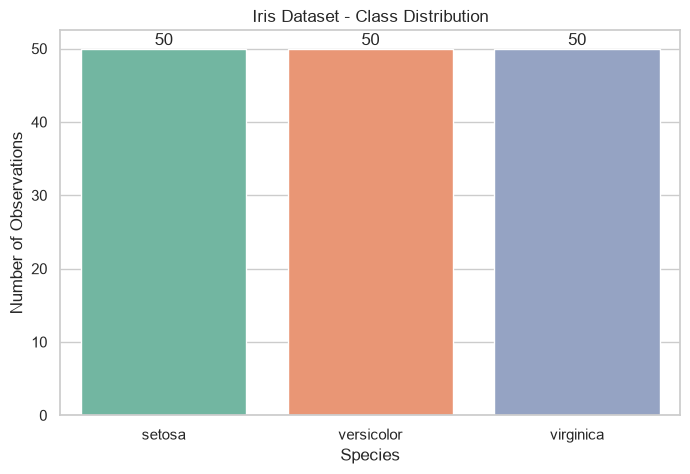

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='species',
    hue='species',
    palette='Set2',
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Iris Dataset - Class Distribution')
plt.xlabel('Species')
plt.ylabel('Number of Observations')
plt.show()

As we can seen the Iris data set is balanced; hence, SMOTE and class weights are unnecessary here.

**Model Development — Baseline Training and Cross-Validation**

In this phase, we develop and evaluate three classification models: Logistic Regression, Random Forest, and XGBoost. We use Scikit-learn pipelines to combine preprocessing and model training while preventing data leakage. Each model is evaluated using 5-fold stratified cross-validation, measuring accuracy, macro F1-score, and ROC-AUC. These initial results establish a performance baseline for comparison before feature selection and hyperparameter optimization.

In [23]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=RANDOM_STATE)
models={
 'Logistic Regression':Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),('model',LogisticRegression(max_iter=3000,random_state=RANDOM_STATE))]),
 'Random Forest':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=200,random_state=RANDOM_STATE,n_jobs=1))]),
 'XGBoost':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',XGBClassifier(n_estimators=150,max_depth=3,learning_rate=.08,subsample=.9,colsample_bytree=.9,objective='multi:softprob',eval_metric='mlogloss',random_state=RANDOM_STATE,n_jobs=1))])}
scoring={'accuracy':'accuracy','f1_macro':'f1_macro','roc_auc_ovr':'roc_auc_ovr'}
baseline_rows=[]
for name,pipe in models.items():
    scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=1)
    baseline_rows.append({'Model':name,**{metric:scores['test_'+metric].mean() for metric in scoring},'Accuracy SD':scores['test_accuracy'].std()})
baseline=pd.DataFrame(baseline_rows).sort_values('f1_macro',ascending=False)
display(baseline.round(3))

,Model,accuracy,f1_macro,roc_auc_ovr,Accuracy SD
0,Logistic Regression,0.958,0.958,0.998,0.026
2,XGBoost,0.950,0.950,0.992,0.031
1,Random Forest,0.950,0.949,0.999,0.031


The baseline results show that all three classification models perform exceptionally well on the Iris dataset. Logistic Regression achieves the highest accuracy (95.8%) and macro F1-score (95.8%), followed by XGBoost (95.0%) and Random Forest (95.0% accuracy and 94.9% F1). Random Forest achieves the highest ROC-AUC (0.999), indicating excellent ability to distinguish between the three species, followed closely by Logistic Regression (0.998) and XGBoost (0.992). Logistic Regression also has the lowest accuracy standard deviation (0.026), suggesting slightly more consistent performance across cross-validation folds.

Conclusion: Logistic Regression is currently the strongest baseline model based on accuracy, F1-score, and consistency, while Random Forest performs marginally better in ROC-AUC. However, the differences are small and may reflect variation in the cross-validation splits. Next, we will explore feature selection and hyperparameter tuning to determine whether these models can be improved.

Note: These are averages from 5-fold cross-validation on the training data, not final test-data.ROC-AUC of 0.999 does not mean 99.9% accuracy. It measures how effectively the model ranks each species against the others in the One-vs-Rest evaluation. For now, Logistic Regression is the leading candidate, but we should wait until the final evaluation before selecting the best model.

Feature selection

let's use three feature selection methods to determine whether all four Iris features are necessary for classification Recursive Feature Elimination (RFE), L1 Regularization (Lasso-style Feature Selection) etc. 

In [25]:
selection_experiments={
 'All four features':models['Logistic Regression'],
 'RFE (3 of 4)':Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),
      ('select',RFE(LogisticRegression(max_iter=3000,random_state=RANDOM_STATE),n_features_to_select=3)),
      ('model',LogisticRegression(max_iter=3000,random_state=RANDOM_STATE))]),
 'L1 selection':Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),
      ('select',SelectFromModel(LogisticRegression(penalty='l1',solver='saga',C=1,max_iter=5000,random_state=RANDOM_STATE),threshold=1e-8)),
      ('model',LogisticRegression(max_iter=3000,random_state=RANDOM_STATE))])}
selection_rows=[]
for name,pipe in selection_experiments.items():
    s=cross_validate(pipe,X_train,y_train,cv=cv,scoring='f1_macro',n_jobs=1)
    selection_rows.append({'Selection method':name,'Mean CV F1 macro':s['test_score'].mean()})
display(pd.DataFrame(selection_rows).sort_values('Mean CV F1 macro',ascending=False).round(3))

C:\Users\husse\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\husse\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\husse\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

,Selection method,Mean CV F1 macro
0,All four features,0.958
1,RFE (3 of 4),0.958
2,L1 selection,0.958


Feature Selection Results: Three feature selection approaches were evaluated using cross-validation and the macro-averaged F1-score: all four original features, Recursive Feature Elimination (RFE), and L1 regularization. All three methods achieved a mean F1-macro score of approximately 0.958, indicating comparable classification performance. RFE demonstrated that reducing the feature set from four to three did not meaningfully affect predictive performance. Similarly, L1-based selection maintained the baseline score. These findings suggest that some features may be redundant and that feature selection can simplify the model without sacrificing classification accuracy. However, the final selection should also consider the number of retained features, cross-validation variability, and performance on an untouched test set.

**Hyperparameter tuning**

In [26]:
grids={
 'Logistic Regression':{'model__C':[.01,.1,1,10,100]},
 'Random Forest':{'model__max_depth':[2,4,None],'model__min_samples_leaf':[1,2,4],'model__max_features':['sqrt',None]},
 'XGBoost':{'model__max_depth':[2,3,4],'model__learning_rate':[.03,.1],'model__n_estimators':[80,160],'model__subsample':[.8,1.0]}}
searches={}
for name,pipe in models.items():
    search=GridSearchCV(pipe,grids[name],scoring='f1_macro',cv=cv,n_jobs=1,refit=True)
    search.fit(X_train,y_train)
    searches[name]=search
    print(name,'CV F1 macro:',round(search.best_score_,3),'best params:',search.best_params_)
comparison=pd.DataFrame([{'Model':name,'CV F1 macro':search.best_score_} for name,search in searches.items()]).sort_values('CV F1 macro',ascending=False)
display(comparison.round(3))

Logistic Regression CV F1 macro: 0.966 best params: {'model__C': 10}
Random Forest CV F1 macro: 0.966 best params: {'model__max_depth': 2, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}
XGBoost CV F1 macro: 0.966 best params: {'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 80, 'model__subsample': 1.0}


,Model,CV F1 macro
0,Logistic Regression,0.966
1,Random Forest,0.966
2,XGBoost,0.966


Hyperparameter tuning was performed on three classification models—Logistic Regression, Random Forest, and XGBoost—to identify the optimal parameter combinations and improve predictive performance. Each model was evaluated using cross-validation with the macro-averaged F1-score as the performance metric. Logistic Regression achieved its best score with a regularization parameter (C) of 10, indicating relatively weak regularization. Random Forest performed best with a maximum tree depth of 2, suggesting that relatively simple decision trees are sufficient to classify Iris species effectively. XGBoost achieved its best results with a learning rate of 0.03, maximum tree depth of 3, and 80 estimators. All three models achieved an identical rounded cross-validation F1-macro score of 0.966 (96.6%), indicating excellent and nearly equivalent classification performance. These results suggest that the Iris dataset can be classified effectively using both simpler linear models and more complex ensemble methods. Since none of the models demonstrated a clear performance advantage, Logistic Regression may be preferred for its simplicity, computational efficiency, and interpretability. However, final model selection should be based on performance on the held-out test dataset, along with other evaluation metrics such as the confusion matrix, precision, recall, and ROC-AUC.

**Model comparison on validation folds**

In [27]:
oof_probs={}
for name,search in searches.items():
    oof_probs[name]=cross_val_predict(search.best_estimator_,X_train,y_train,cv=cv,method='predict_proba',n_jobs=1)
rows=[]
for name,probs in oof_probs.items():
    preds=probs.argmax(axis=1)
    rows.append({'Model':name,'OOF accuracy':accuracy_score(y_train,preds),
                 'OOF precision macro':precision_score(y_train,preds,average='macro',zero_division=0),
                 'OOF recall macro':recall_score(y_train,preds,average='macro',zero_division=0),
                 'OOF F1 macro':f1_score(y_train,preds,average='macro'),
                 'OOF ROC-AUC OvR':roc_auc_score(y_train,probs,multi_class='ovr',average='macro')})
display(pd.DataFrame(rows).sort_values('OOF F1 macro',ascending=False).round(3))

,Model,OOF accuracy,OOF precision macro,OOF recall macro,OOF F1 macro,OOF ROC-AUC OvR
0,Logistic Regression,0.967,0.967,0.967,0.967,0.997
1,Random Forest,0.967,0.967,0.967,0.967,0.996
2,XGBoost,0.967,0.967,0.967,0.966,0.994


Model Comparison Using Out-of-Fold Cross-Validation
After hyperparameter tuning, we compared the performance of Logistic Regression, Random Forest, and XGBoost using out-of-fold (OOF) predictions generated through cross-validation. Unlike the previous step, which focused on finding the best hyperparameters using the F1-macro score, this step evaluates each tuned model across multiple classification metrics: accuracy, precision, recall, F1-macro, and ROC-AUC. Out-of-fold predictions ensure that each training observation is evaluated by a model that was not trained on that observation during the current cross-validation run.
Results and Interpretation
All three models demonstrated excellent and nearly identical performance:
- Accuracy (~96.7%): Approximately 96.7% of Iris observations were correctly classified.
- Precision (~96.7%): When the models predicted a particular species, their predictions were correct approximately 96.7% of the time, averaged equally across species.
- Recall (~96.7%): The models successfully identified approximately 96.7% of observations belonging to each species, averaged equally across species.
- F1-macro (~96.6–96.7%): All models achieved nearly identical balances between precision and recall.
- ROC-AUC (99.4–99.7%): All models demonstrated excellent ability to distinguish between the three Iris species, with Logistic Regression achieving the highest score (0.997).
Overall Conclusion
Logistic Regression performed marginally better overall, achieving the highest ROC-AUC score (0.997), followed by Random Forest (0.996) and XGBoost (0.994). However, these differences are extremely small, and all three models achieved nearly identical classification performance. Given its simplicity, interpretability, and computational efficiency, Logistic Regression is a strong candidate for the final model.

Important methodological note: Because these OOF predictions use hyperparameters already selected from the same training data, the scores may be slightly optimistic. Nested cross-validation would provide a more rigorous estimate of performance after tuning. The next step is to evaluate the selected models on the untouched test dataset using confusion matrices, classification reports, and ROC curves before making a final selection.

**Multiclass ROC and precision-recall curves**

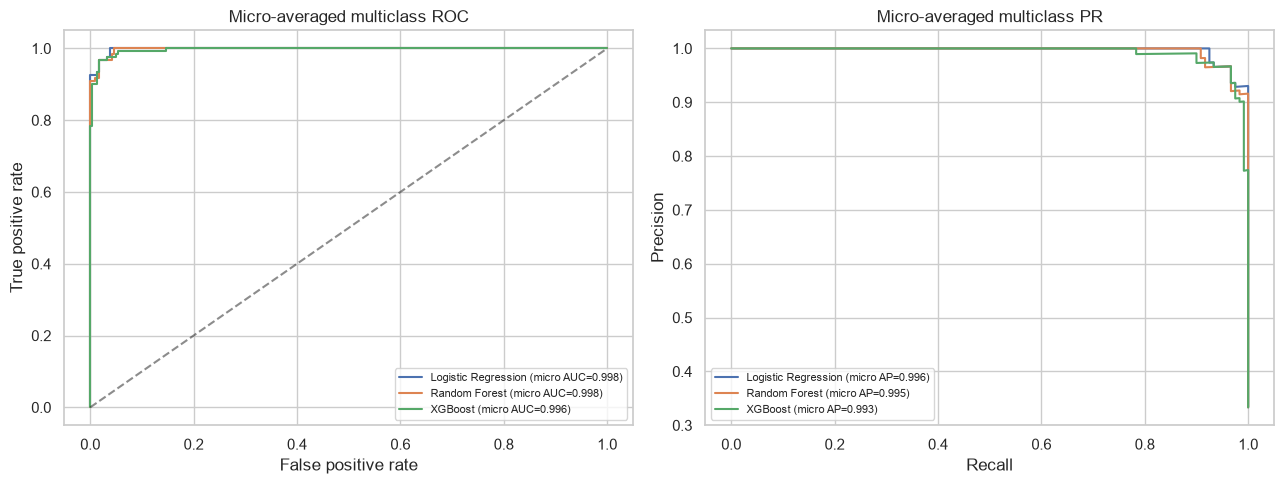

Note: these plots show micro-averaging; the comparison table uses macro one-vs-rest ROC-AUC.


In [28]:
y_bin=label_binarize(y_train,classes=[0,1,2])
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,probs in oof_probs.items():
    fpr,tpr,_=roc_curve(y_bin.ravel(),probs.ravel())
    axes[0].plot(fpr,tpr,label=f'{name} (micro AUC={auc(fpr,tpr):.3f})')
    precision,recall,_=precision_recall_curve(y_bin.ravel(),probs.ravel())
    ap=average_precision_score(y_bin,probs,average='micro')
    axes[1].plot(recall,precision,label=f'{name} (micro AP={ap:.3f})')
axes[0].plot([0,1],[0,1],'k--',alpha=.5)
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Micro-averaged multiclass ROC')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Micro-averaged multiclass PR')
for ax in axes:ax.legend(fontsize=8)
plt.tight_layout();plt.show()
print('Note: these plots show micro-averaging; the comparison table uses macro one-vs-rest ROC-AUC.')

We evaluated Logistic Regression, Random Forest, and XGBoost using micro-averaged ROC and Precision-Recall (PR) curves generated from out-of-fold cross-validation predictions on the training dataset. The ROC curves measure the trade-off between the True Positive Rate and False Positive Rate, while the PR curves evaluate the relationship between precision and recall across different classification thresholds. All three models demonstrated excellent performance, achieving ROC-AUC scores between 0.996 and 0.998 and average precision scores between 0.993 and 0.996. Logistic Regression and Random Forest performed marginally better than XGBoost, although the differences were negligible. The ROC curves remain close to the upper-left corner, while the PR curves maintain high precision across nearly all recall levels, indicating strong classification performance. These evaluations were performed using cross-validation on the training data only, leaving the test dataset untouched for final model evaluation.

**Threshold tuning in multiclass Iris**

,threshold,precision,recall,f1
1,0.15,0.909,1.000,0.952
3,0.25,0.909,1.000,0.952
2,0.20,0.909,1.000,0.952
7,0.45,0.950,0.950,0.950
8,0.50,0.950,0.950,0.950
10,0.60,0.950,0.950,0.950
9,0.55,0.950,0.950,0.950
4,0.30,0.907,0.975,0.940
6,0.40,0.927,0.950,0.938
11,0.65,0.949,0.925,0.937


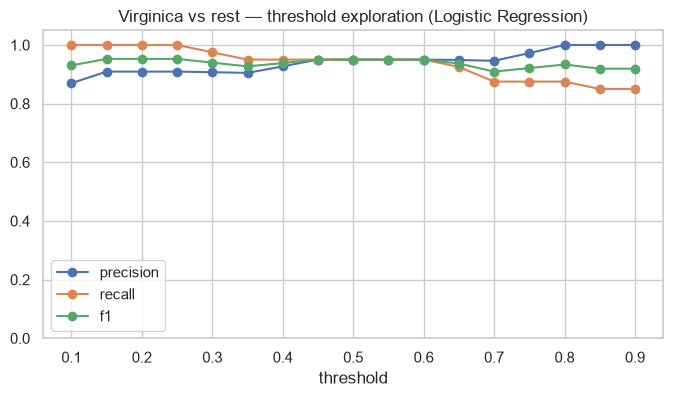

In [29]:
winner_name=comparison.iloc[0]['Model']
winner=searches[winner_name].best_estimator_
virginica_proba=oof_probs[winner_name][:,2]
virginica_true=(y_train.to_numpy()==2).astype(int)
threshold_rows=[]
for threshold in np.arange(.10,.91,.05):
    pred=(virginica_proba>=threshold).astype(int)
    threshold_rows.append({'threshold':round(float(threshold),2),
        'precision':precision_score(virginica_true,pred,zero_division=0),
        'recall':recall_score(virginica_true,pred,zero_division=0),
        'f1':f1_score(virginica_true,pred,zero_division=0)})
threshold_df=pd.DataFrame(threshold_rows)
display(threshold_df.sort_values('f1',ascending=False).head(10).round(3))
threshold_df.set_index('threshold')[['precision','recall','f1']].plot(marker='o',figsize=(8,4))
plt.title(f'Virginica vs rest — threshold exploration ({winner_name})');plt.ylim(0,1.05);plt.show()

We performed threshold tuning to determine the optimal probability cutoff for classifying Iris Virginica versus the other two species using our selected Logistic Regression model. Instead of relying on the default classification threshold of 0.50, we tested thresholds ranging from 0.10 to 0.90 to examine how changing the cutoff affects precision, recall, and F1-score. Lower thresholds generally increased recall but reduced precision, while higher thresholds improved precision at the expense of recall. The results showed that thresholds between 0.15 and 0.25 achieved the highest F1-score of 0.952, with precision of 0.909 and recall of 1.000, meaning all Virginica observations were identified, although some other species were incorrectly classified as Virginica. However, the default threshold of 0.50 achieved a nearly identical F1-score of 0.950, with a more balanced precision and recall of 0.950 each. Therefore, retaining the default threshold of 0.50 is a reasonable choice, since lowering it provides only a marginal F1 improvement while increasing false positives. This analysis was performed using training-data cross-validation predictions, leaving the test dataset untouched for final evaluation.

**Final held-out test evaluation**

Selected by training CV: Logistic Regression
Test accuracy: 1.0
Test macro F1: 1.0
Test macro ROC-AUC OvR: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



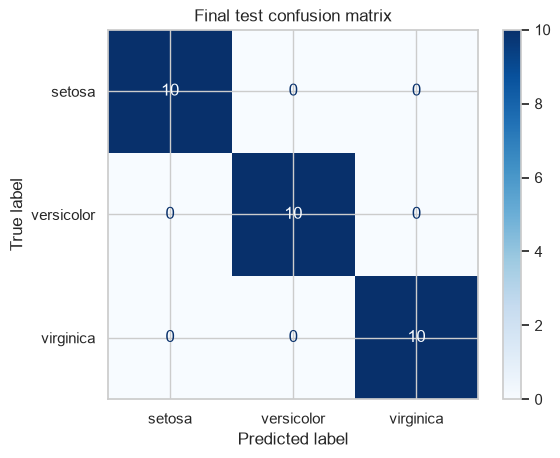

In [31]:
test_probs=winner.predict_proba(X_test)
test_pred=winner.predict(X_test)
print('Selected by training CV:',winner_name)
print('Test accuracy:',round(accuracy_score(y_test,test_pred),3))
print('Test macro F1:',round(f1_score(y_test,test_pred,average='macro'),3))
print('Test macro ROC-AUC OvR:',round(roc_auc_score(y_test,test_probs,multi_class='ovr',average='macro'),3))
print(classification_report(y_test,test_pred,target_names=iris.target_names,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=iris.target_names,cmap='Blues')
plt.title('Final test confusion matrix');plt.show()

**Final Held-Out Test Evaluation – Results and Interpretation**

After completing feature selection, hyperparameter tuning, cross-validation, and model comparison, we evaluated the selected Logistic Regression model on the previously unseen test dataset to assess its ability to generalize to new observations. The model achieved 100% accuracy, 100% macro-averaged precision, recall, F1-score, and ROC-AUC, demonstrating perfect classification performance on the 30 test observations. The confusion matrix confirms that all 10 Setosa, 10 Versicolor, and 10 Virginica flowers were correctly classified, with zero misclassifications. These results are consistent with the strong cross-validation performance observed earlier and suggest that Logistic Regression is highly effective for classifying Iris species. However, because the test dataset contains only 30 observations, perfect performance does not guarantee equally accurate predictions on all future data.

Overall, Logistic Regression was selected as the final model because it combines excellent predictive performance with simplicity, computational efficiency, and interpretability.

**Feature importance / interpretability**

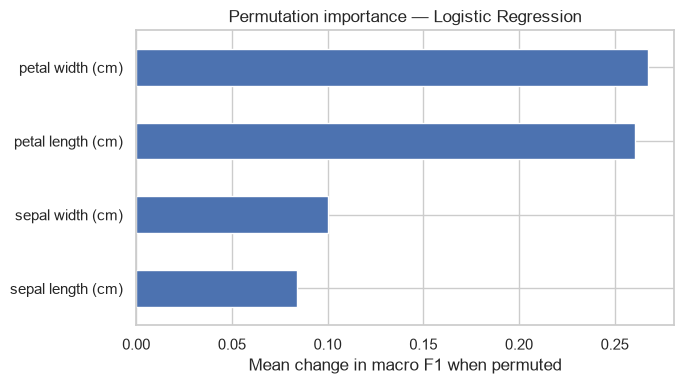

Note: permutation importance on the test set is diagnostic only; do not use it to revise the model and then claim an untouched test.


In [33]:
perm=permutation_importance(winner,X_test,y_test,scoring='f1_macro',n_repeats=20,random_state=RANDOM_STATE)
importance=pd.Series(perm.importances_mean,index=X.columns).sort_values()
importance.plot.barh(figsize=(7,4));plt.xlabel('Mean change in macro F1 when permuted');plt.title(f'Permutation importance — {winner_name}');plt.tight_layout();plt.show()
print('Note: permutation importance on the test set is diagnostic only; do not use it to revise the model and then claim an untouched test.')

Feature Importance and Model Interpretability – Results and Interpretation
After evaluating the final Logistic Regression model, we performed permutation feature importance analysis to identify which Iris features contribute most to classification performance. This technique measures feature importance by randomly shuffling each feature's values and observing how much the model's F1-macro score decreases. A larger decrease indicates that the model relies more heavily on that feature for accurate predictions. The results show that petal width (0.27) and petal length (0.26) are the most important features, followed by sepal width (0.10) and sepal length (0.08). This indicates that petal measurements play a significantly greater role in distinguishing between Iris species than sepal measurements. Overall, the analysis provides insight into how the model makes predictions and confirms that petal characteristics are the strongest predictors of Iris species. Because permutation importance was calculated using the test dataset, these findings should be used for model interpretation only, not for further feature selection or model tuning, which would compromise the independence of the final test evaluation.